# 06 — Final evaluation on the test set

**Goal:** measure, once and honestly, how well each model prices phones it has **never seen**. Until now every score came from grouped cross-validation on the 558 training phones; the 144 test phones (20 % of the phone models, set aside in Phase 3) have not been used by any model, plot or decision.

**Ground rules**
- **The test set is used once.** No model, feature or hyperparameter may be changed after seeing the test results. If a bug is found, only the bug is fixed, everything is rerun, and this is recorded in the note *"Changes after unlocking the test set"* at the end of this notebook.
- **Nothing is tuned here.** All settings come from `results/best_params.json` (saved in Phase 6). Each model is refitted on the full training set with those settings and then predicts the test phones.

Same metrics as before (R² on log price, median % price error, MAE in ₹), plus the **median absolute error in ₹** (half of the phones are off by less than this many rupees).

## 7.1 Setup
Libraries, the saved settings, and the train/test data. The assert checks the most important property of the split: no phone model (all its storage variants) appears on both sides.

In [1]:
import sys
sys.path.insert(0, "../src")
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import joblib
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, AdaBoostRegressor

from features import NUMERIC_FEATURES
from split import load_train_test

Load the data and the chosen settings, and check the split.

In [2]:
pd.set_option("display.width", 200)
CATEGORICAL = ["chip_group", "brand"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL
best_params = json.load(open("../results/best_params.json"))

train, test = load_train_test(include_web_lookup=True)
shared = set(train["model_group"]) & set(test["model_group"])
assert len(shared) == 0, f"{len(shared)} phone models are in both train and test"
for name, data in [("train", train), ("test", test)]:
    print(f"{name}: {len(data)} phones, {data['model_group'].nunique()} phone models (model groups)")
print("phone models in both sets:", len(shared))

train: 558 phones, 380 phone models (model groups)
test: 144 phones, 95 phone models (model groups)
phone models in both sets: 0


**What is in the test set?** Test phones per brand and per price band. The bands are the same as in Phase 6: under ₹15,000, ₹15–30k, ₹30–60k and ₹60k or more.

In [3]:
def price_band(price):
    return pd.cut(price, [0, 15000, 30000, 60000, np.inf], right=False,
                  labels=["< ₹15k", "₹15–30k", "₹30–60k", "₹60k+"])

print("Test phones per brand:\n", test["brand"].value_counts().to_string())
print("\nTest phones per price band:\n", price_band(test["price_inr"]).value_counts().sort_index().to_string())

Test phones per brand:
 brand
Vivo        29
Apple       21
Oppo        15
Xiaomi      13
Motorola    12
Infinix     12
Realme       8
Samsung      7
OnePlus      6
POCO         5
Google       4
Tecno        4
Nokia        3
Other        3
Lenovo       2

Test phones per price band:
 price_inr
< ₹15k     29
₹15–30k    42
₹30–60k    32
₹60k+      41


**Takeaway:** the test set has **144 phones from 95 phone models**, and no phone model is in both sets. The brand mix differs from training: Vivo (29) and Apple (21) are the largest test brands, while Samsung, our largest training brand after Oppo, has only 7 test phones. Five brands have fewer than 5 test phones (Google 4, Tecno 4, Nokia 3, Other 3, Lenovo 2), so any per-brand result for them is anecdotal. The price bands are reasonably balanced (29 / 42 / 32 / 41 phones). With only ~140 phones, every test number below carries real uncertainty; section 7.4 measures how much.

**Categories the models have never seen.** If a brand or chip group appears in the test set but not in the training set, the models have no coefficient or split for it. `OneHotEncoder(handle_unknown="ignore")` then encodes it as all zeros: for ridge and OLS it behaves like the reference category, and for trees it simply goes the "not this category" way at every brand/chip question.

In [4]:
for col in CATEGORICAL:
    unseen = sorted(set(test[col]) - set(train[col]))
    print(f"{col}: categories in test but not in train: {unseen if unseen else 'none'}")

chip_group: categories in test but not in train: ['other']
brand: categories in test but not in train: none


## 7.2 Refit every model on the full training set and predict the test phones
Three kinds of pipeline, exactly as in the earlier notebooks:
- **OLS (Models A and B):** numeric features as they are, plus dummies with one **reference category dropped** (`snapdragon_other`, `Samsung`), fitted with `LinearRegression`. This is the same design matrix and the same fit as `fit_ols` in 03_linear_simple; the in-sample R² printed below must match Phase 4 (A 0.799, B 0.873).
- **Ridge, lasso, elastic net:** standardised numerics plus all dummies (Phase 5).
- **Trees:** numerics unchanged plus all dummies (Phase 6).

In [5]:
def make_ols_pipeline(categorical, reference):
    # drop= removes the reference category of each categorical feature (as in 03_linear_simple);
    # an unseen category is encoded as all zeros, i.e. like the reference
    pre = ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OneHotEncoder(drop=reference, handle_unknown="ignore", sparse_output=False), categorical)])
    return Pipeline([("pre", pre), ("model", LinearRegression())])

def make_linear_pipeline(model):
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)])
    return Pipeline([("pre", pre), ("model", model)])

def make_tree_pipeline(model):
    pre = ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)])
    return Pipeline([("pre", pre), ("model", model)])

All models with their Phase 5–6 settings. The order is the order of the tables below.

In [6]:
p = best_params
pipelines = {
    "Model A: specs + chip": make_ols_pipeline(["chip_group"], ["snapdragon_other"]),
    "Model B: specs + chip + brand": make_ols_pipeline(CATEGORICAL, ["snapdragon_other", "Samsung"]),
    "Ridge": make_linear_pipeline(Ridge(alpha=p["ridge"]["alpha"])),
    "Lasso": make_linear_pipeline(Lasso(alpha=p["lasso"]["alpha"], max_iter=50000)),
    "Elastic net": make_linear_pipeline(ElasticNet(**p["elastic_net"], max_iter=50000)),
    "Decision tree (depth 3)": make_tree_pipeline(DecisionTreeRegressor(max_depth=3, random_state=42)),
    "Decision tree (best depth)": make_tree_pipeline(DecisionTreeRegressor(**p["decision_tree"], random_state=42)),
    "Random forest": make_tree_pipeline(RandomForestRegressor(**p["random_forest"], random_state=42, n_jobs=-1)),
    "Gradient boosting": make_tree_pipeline(GradientBoostingRegressor(**p["gradient_boosting"], random_state=42)),
}
if "adaboost" in p:
    ada = dict(p["adaboost"])
    tree = DecisionTreeRegressor(max_depth=ada.pop("estimator__max_depth"), random_state=42)   # AdaBoost's base tree
    pipelines["AdaBoost"] = make_tree_pipeline(AdaBoostRegressor(estimator=tree, **ada, random_state=42))
if "xgboost" in p:   # only if XGBoost was run in Phase 6
    from xgboost import XGBRegressor
    pipelines["XGBoost"] = make_tree_pipeline(XGBRegressor(**p["xgboost"], random_state=42, n_jobs=-1))

**Fit and predict.** The two baselines need no pipeline: Baseline 1 predicts the training mean log price for every phone; Baseline 2 predicts the training mean of the phone's brand (the overall mean for a brand never seen in training). Every other model is fitted on all 558 training phones and predicts the test phones' log price.

In [7]:
y_train, y_test = train["log_price"], test["log_price"]
pred = {}   # model name -> predicted log price for every test phone
pred["Baseline 1: overall mean"] = np.full(len(test), y_train.mean())
brand_means = train.groupby("brand")["log_price"].mean()
pred["Baseline 2: brand mean"] = test["brand"].map(brand_means).fillna(y_train.mean()).to_numpy()

fitted = {}
for name, pipe in pipelines.items():
    fitted[name] = pipe.fit(train[FEATURES], y_train)
    pred[name] = fitted[name].predict(test[FEATURES])

for name in ["Model A: specs + chip", "Model B: specs + chip + brand"]:   # check against Phase 4
    in_sample = fitted[name].predict(train[FEATURES])
    r2 = 1 - np.sum((y_train - in_sample) ** 2) / np.sum((y_train - y_train.mean()) ** 2)
    print(f"{name}: in-sample R² on the training set = {r2:.3f}")

/media/Disk2/Machine_Learning_projects/phone-price-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/media/Disk2/Machine_Learning_projects/phone-price-project/.venv/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Model A: specs + chip: in-sample R² on the training set = 0.799
Model B: specs + chip + brand: in-sample R² on the training set = 0.873


**Save the predictions and three fitted models.** The predictions go to `results/test_predictions.csv` (log price and ₹ for every model). Ridge (interpretable, used for the brand premium in Phase 8), Model A (the "hardware value" model, also for Phase 8) and gradient boosting (the most accurate in CV) are saved with **joblib**, which stores a fitted Python object in a file so Phases 8–9 can reuse it without refitting.

*Note on exp():* our models predict the **mean of log price**. exp(mean of log) is not the mean price but a typical, median-like price (for a skewed price distribution it is lower than the mean). We accept this because all errors are judged in percentages, where a typical price is the right target.

In [8]:
out = test[["Model Name", "brand", "model_group", "price_inr"]].copy()
for name, p_log in pred.items():
    out[f"log_pred | {name}"] = p_log
    out[f"₹_pred | {name}"] = np.exp(p_log).round()
out.to_csv("../results/test_predictions.csv", index_label="row")

Path("../models").mkdir(exist_ok=True)
for name, file in [("Ridge", "ridge"), ("Model A: specs + chip", "model_a_ols"), ("Gradient boosting", "gradient_boosting")]:
    joblib.dump(fitted[name], f"../models/{file}.joblib")
print("Saved results/test_predictions.csv and models/ridge.joblib, model_a_ols.joblib, gradient_boosting.joblib")

Saved results/test_predictions.csv and models/ridge.joblib, model_a_ols.joblib, gradient_boosting.joblib


## 7.3 Test scores
The same `score()` function as notebooks 03–05, with one extra column: the **median absolute error in ₹**. Unlike the MAE (a mean, pulled up by a few very expensive phones), half of the test phones are priced within this many rupees.

In [9]:
def score(y_true_log, y_pred_log):
    y_true_log, y_pred_log = np.asarray(y_true_log), np.asarray(y_pred_log)
    # R² = 1 − RSS / TSS, on the log scale
    r2 = 1 - np.sum((y_true_log - y_pred_log) ** 2) / np.sum((y_true_log - y_true_log.mean()) ** 2)
    price_true, price_pred = np.exp(y_true_log), np.exp(y_pred_log)   # back to rupees
    return {"R²": r2,
            "median % error": 100 * np.median(np.abs(price_pred / price_true - 1)),
            "MAE (₹)": np.mean(np.abs(price_pred - price_true)),
            "median abs error (₹)": np.median(np.abs(price_pred - price_true))}

test_scores = pd.DataFrame({name: score(y_test, p_log) for name, p_log in pred.items()}).T
test_scores.index.name = "model"
test_scores.sort_values("median % error").round({"R²": 3, "median % error": 1, "MAE (₹)": 0, "median abs error (₹)": 0})

,R²,median % error,MAE (₹),median abs error (₹)
model,,,,
Gradient boosting,0.932,12.4,6050.0,3855.0
Random forest,0.925,12.7,6369.0,4077.0
AdaBoost,0.926,13.3,6328.0,4890.0
Decision tree (best depth),0.846,16.7,8693.0,6055.0
Lasso,0.855,20.9,10146.0,5792.0
Elastic net,0.854,21.0,10157.0,5832.0
Ridge,0.849,21.5,10443.0,6617.0
Decision tree (depth 3),0.795,21.6,10514.0,7264.0
Model B: specs + chip + brand,0.851,21.6,10580.0,6913.0


**Cross-validation vs test.** Each model's grouped-CV score from Phase 6 (`results/cv_phase6.csv`) next to its test score. "CV − test" > 0 for R² means the model did worse on the test set than in CV; for median % error the sign is reversed (test − CV > 0 means worse on test).

In [10]:
cv = pd.read_csv("../results/cv_phase6.csv").set_index("model")
versus = pd.DataFrame({
    "CV R²": cv["R2_log_mean"], "test R²": test_scores["R²"],
    "CV median %": cv["median_pct_error_mean"], "test median %": test_scores["median % error"]})
versus["R²: CV − test"] = versus["CV R²"] - versus["test R²"]
versus["median %: test − CV"] = versus["test median %"] - versus["CV median %"]
versus = versus.loc[test_scores.sort_values("median % error").index]
versus.round(3)

,CV R²,test R²,CV median %,test median %,R²: CV − test,median %: test − CV
model,,,,,,
Gradient boosting,0.914,0.932,12.708,12.357,-0.018,-0.351
Random forest,0.909,0.925,13.171,12.687,-0.016,-0.484
AdaBoost,0.916,0.926,11.563,13.334,-0.010,1.771
Decision tree (best depth),0.832,0.846,16.125,16.679,-0.014,0.554
Lasso,0.848,0.855,18.037,20.900,-0.007,2.863
Elastic net,0.848,0.854,18.129,20.959,-0.006,2.830
Ridge,0.847,0.849,18.343,21.533,-0.002,3.191
Decision tree (depth 3),0.675,0.795,26.354,21.551,-0.121,-4.803
Model B: specs + chip + brand,0.845,0.851,18.206,21.583,-0.006,3.377


**Takeaway — gradient boosting is the best model on unseen phones.** It reaches test **R² 0.932**, a median error of **12.4 %**, MAE **₹6,050** and a median absolute error of **₹3,855**. The random forest is a close second (0.925, 12.7 %). **AdaBoost** (added later, settings fixed by cross-validation) reaches R² 0.926 and 13.3 %, on a par with the forest. The best linear models (lasso, elastic net, ridge, OLS Model B) reach R² 0.85 and a median error of about **21 %**. The baselines are far behind (brand mean 33.5 %, overall mean 58.7 %), and the single trees are in between.

**CV vs test.** We expected a small drop from CV to test, larger for the heavily tuned tree models. That is **not** what happened:
- **Tree ensembles:** they did *slightly better* on the test set than in CV (boosting R² 0.914 → 0.932, median error 12.7 % → 12.4 %).
- **Linear models:** they kept their R² (ridge 0.847 → 0.849), but their median error rose by about 3 points (ridge 18.3 % → 21.5 %).
- **AdaBoost:** it is the one tree ensemble whose median error rose from CV to test (11.6 % → 13.3 %; R² 0.916 → 0.926). It had the largest tuning grid (108 settings), so its CV score had the most room for optimism. The change is still inside the test-set noise.
- **Why:** these changes are about the size of the test-set noise (next section). The test set also has a different brand mix: it has more Apple and Vivo phones, few Samsung phones, and the brand-mean baseline does much better on it (R² 0.51 vs 0.37 in CV). So this test set simply happens to be a little "easier" for some models and "harder" for others. The honest conclusion is that we see **no sign of tuning optimism large enough to measure with 144 phones**. It is not evidence that tuning made the trees better than CV said.

(The warning printed when the OLS models predict refers to one test phone, the Vivo X3S, whose old MediaTek MT6592 chip falls in the `other` chip group, which has no training phone. It is encoded as all zeros, as explained in 7.1.)

## 7.4 How certain are these numbers? Bootstrap
144 test phones is a small sample: with a different set of test phones every number above would change a little. The **bootstrap** estimates how much. We draw a new "test set" of the same size by sampling the test **phone models** (model groups) **with replacement**, so some models appear twice and some not at all, and a model's storage variants always stay together (they are not independent phones). We recompute every metric on this resample, repeat 1,000 times, and take the 2.5th and 97.5th percentiles of the 1,000 values as a **95 % interval**.

All models are scored on the **same** 1,000 resamples, so differences between two models can be computed **paired** (model 1 − model 2 on each resample). That removes the noise of "this resample happened to contain easy phones", which affects both models equally.

In [11]:
rng = np.random.default_rng(42)
group_rows = [np.flatnonzero(test["model_group"].to_numpy() == g) for g in test["model_group"].unique()]
models = list(pred)
boot = {m: {"R²": [], "median % error": []} for m in models}
for b in range(1000):
    chosen = rng.integers(0, len(group_rows), size=len(group_rows))      # model groups, with replacement
    rows = np.concatenate([group_rows[g] for g in chosen])               # all their test phones
    for m in models:
        s = score(y_test.to_numpy()[rows], pred[m][rows])
        boot[m]["R²"].append(s["R²"])
        boot[m]["median % error"].append(s["median % error"])
boot = {m: {k: np.array(v) for k, v in d.items()} for m, d in boot.items()}

intervals = pd.DataFrame({m: {
    "R²": test_scores.loc[m, "R²"], "R² low": np.percentile(boot[m]["R²"], 2.5), "R² high": np.percentile(boot[m]["R²"], 97.5),
    "median %": test_scores.loc[m, "median % error"],
    "median % low": np.percentile(boot[m]["median % error"], 2.5),
    "median % high": np.percentile(boot[m]["median % error"], 97.5)} for m in models}).T
intervals.sort_values("median %").round(3)

,R²,R² low,R² high,median %,median % low,median % high
Gradient boosting,0.932,0.897,0.955,12.357,9.627,14.300
Random forest,0.925,0.884,0.951,12.687,10.326,15.841
AdaBoost,0.926,0.887,0.951,13.334,11.648,16.053
Decision tree (best depth),0.846,0.766,0.896,16.679,11.984,20.001
Lasso,0.855,0.793,0.899,20.900,15.752,25.938
Elastic net,0.854,0.792,0.898,20.959,15.437,26.496
Ridge,0.849,0.785,0.896,21.533,15.871,26.254
Decision tree (depth 3),0.795,0.713,0.852,21.551,19.785,28.130
Model B: specs + chip + brand,0.851,0.789,0.896,21.583,15.360,27.052
Model A: specs + chip,0.785,0.683,0.853,23.664,18.254,27.751


**Paired differences.** For each pair, the difference in median % error and in R² (first model − second model) on the same resample, its 95 % interval, and the share of the 1,000 resamples in which the **first** model is better (lower median % error, higher R²). An interval that does not contain 0 means the difference is clearly real, not test-set luck.

In [12]:
pairs = [("Gradient boosting", "Ridge"), ("Random forest", "Ridge"),
         ("Gradient boosting", "Random forest"), ("Ridge", "Model B: specs + chip + brand"),
         ("AdaBoost", "Gradient boosting")]
paired = []
for m1, m2 in pairs:
    d_err = boot[m1]["median % error"] - boot[m2]["median % error"]
    d_r2 = boot[m1]["R²"] - boot[m2]["R²"]
    paired.append({"comparison": f"{m1} − {m2}",
                   "Δ median % (test)": test_scores.loc[m1, "median % error"] - test_scores.loc[m2, "median % error"],
                   "Δ median % low": np.percentile(d_err, 2.5), "Δ median % high": np.percentile(d_err, 97.5),
                   "share 1st better (median %)": np.mean(d_err < 0),
                   "Δ R² (test)": test_scores.loc[m1, "R²"] - test_scores.loc[m2, "R²"],
                   "Δ R² low": np.percentile(d_r2, 2.5), "Δ R² high": np.percentile(d_r2, 97.5),
                   "share 1st better (R²)": np.mean(d_r2 > 0)})
paired = pd.DataFrame(paired).set_index("comparison")
paired.round(3)

,Δ median % (test),Δ median % low,Δ median % high,share 1st better (median %),Δ R² (test),Δ R² low,Δ R² high,share 1st better (R²)
comparison,,,,,,,,
Gradient boosting − Ridge,-9.176,-14.590,-2.758,0.999,0.082,0.044,0.133,1.000
Random forest − Ridge,-8.846,-13.245,-2.738,1.000,0.075,0.040,0.124,1.000
Gradient boosting − Random forest,-0.330,-3.361,1.824,0.725,0.007,-0.011,0.025,0.782
Ridge − Model B: specs + chip + brand,-0.050,-2.132,2.002,0.576,-0.002,-0.007,0.004,0.217
AdaBoost − Gradient boosting,0.977,-1.058,3.520,0.126,-0.006,-0.024,0.010,0.242


**Chart:** each model's test median % error with its 95 % bootstrap interval.

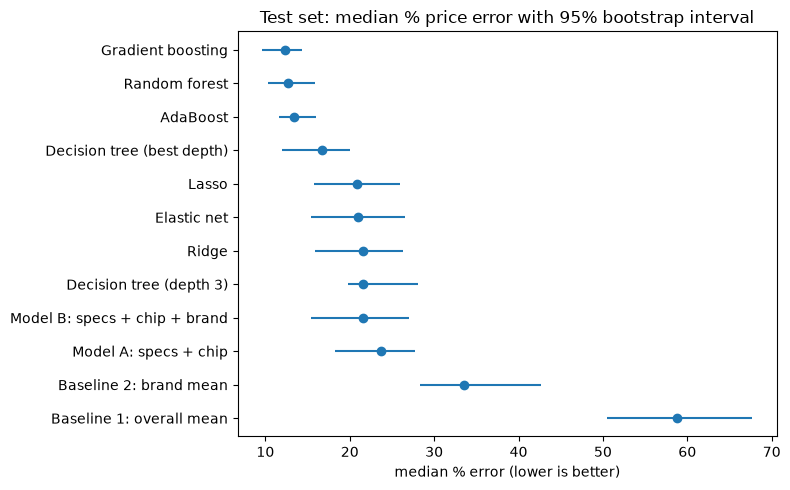

In [13]:
order = intervals.sort_values("median %").index
fig, ax = plt.subplots(figsize=(8, 5))
ypos = np.arange(len(order))
ax.errorbar(intervals.loc[order, "median %"], ypos, fmt="o",
            xerr=[intervals.loc[order, "median %"] - intervals.loc[order, "median % low"],
                  intervals.loc[order, "median % high"] - intervals.loc[order, "median %"]])
ax.set_yticks(ypos, order)
ax.invert_yaxis()
ax.set(title="Test set: median % price error with 95% bootstrap interval", xlabel="median % error (lower is better)")
fig.tight_layout()
fig.savefig("../results/fig07_test_error_intervals.png", dpi=150)
plt.show()

**Takeaway — what is real and what is noise.**
- **Trees vs ridge is clearly real.** Gradient boosting has a **9.2 points lower** median error than ridge (95 % interval **2.8 to 14.6 points**) and **0.082 higher R²** (0.044 to 0.133). It wins in **99.9 %** of the resamples on median error and in **100 %** on R². The random forest vs ridge comparison is almost the same (−8.8 points, interval −13.2 to −2.7). Both intervals exclude 0.
- **Boosting vs forest cannot be separated:** −0.3 points (interval −3.4 to +1.8), and boosting is better in only 73 % of resamples. On this test set they are a tie.
- **Ridge vs OLS (Model B) cannot be separated either:** −0.05 points (−2.1 to +2.0) and an R² difference of −0.002 (−0.007 to +0.004). As in Phase 5, regularisation does not change accuracy; we keep ridge for its stable coefficients.
- **AdaBoost vs gradient boosting cannot be separated:** AdaBoost's median error is 1.0 point higher (interval −1.1 to +3.5), and gradient boosting is better in 87 % of resamples. That is a lean towards gradient boosting, not a clear difference.
- **Width of the intervals:** the individual intervals are wide (boosting's median error 9.6–14.3 %, ridge's 15.9–26.3 %). That is why the CV-to-test changes in 7.3 (a few points) are within noise. The paired intervals are much narrower than the single-model ones, because both models face the same easy or hard phones in each resample.

## 7.5 Predicted vs actual price
Each dot is a test phone: actual price (x) against predicted price (y), both on a **log scale** so that cheap and expensive phones get equal room and a fixed % error is a fixed distance everywhere. Points on the solid line y = x are perfect; between the dashed lines the prediction is within ±20 %.

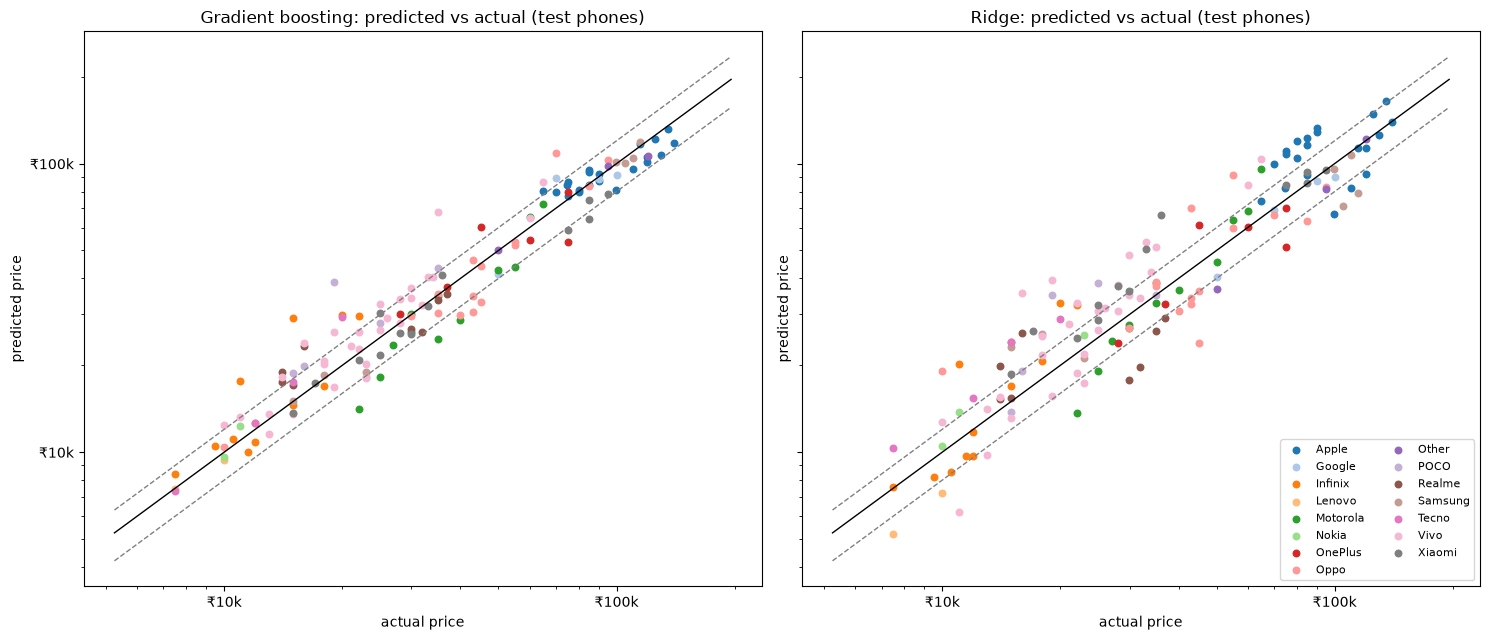

In [14]:
rupee_axis = FuncFormatter(lambda v, _: f"₹{v / 1000:g}k")
brands = sorted(test["brand"].unique())
colours = {b: plt.cm.tab20(i % 20) for i, b in enumerate(brands)}
actual = test["price_inr"].to_numpy()
line = np.array([actual.min() * 0.7, actual.max() * 1.4])

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), sharex=True, sharey=True)
for ax, name in zip(axes, ["Gradient boosting", "Ridge"]):
    for b in brands:
        is_b = (test["brand"] == b).to_numpy()
        ax.scatter(actual[is_b], np.exp(pred[name][is_b]), s=22, color=colours[b], label=b)
    ax.plot(line, line, color="black", linewidth=1)
    ax.plot(line, 1.2 * line, color="gray", linestyle="--", linewidth=1)
    ax.plot(line, 0.8 * line, color="gray", linestyle="--", linewidth=1)
    ax.set(xscale="log", yscale="log", title=f"{name}: predicted vs actual (test phones)",
           xlabel="actual price", ylabel="predicted price")
    ax.xaxis.set_major_formatter(rupee_axis)
    ax.yaxis.set_major_formatter(rupee_axis)
axes[1].legend(fontsize=8, ncol=2, loc="lower right")
fig.tight_layout()
fig.savefig("../results/fig07_pred_vs_actual.png", dpi=150)
plt.show()

The share of test phones priced within ±10 %, ±20 % and ±30 % of their actual price.

In [15]:
within = {}
for name in ["Gradient boosting", "Random forest", "Ridge", "Model B: specs + chip + brand"]:
    pct = 100 * np.abs(np.exp(pred[name]) / actual - 1)
    within[name] = {f"within ±{k} %": f"{np.mean(pct <= k):.0%}" for k in [10, 20, 30]}
pd.DataFrame(within).T

,within ±10 %,within ±20 %,within ±30 %
Gradient boosting,41%,72%,88%
Random forest,39%,70%,90%
Ridge,25%,47%,64%
Model B: specs + chip + brand,24%,44%,63%


**The same chart for the website** as an interactive Plotly figure (hover shows the phone name), saved as JSON so the website can load it.

In [16]:
pfig = make_subplots(rows=1, cols=2, shared_yaxes=True, subplot_titles=["Gradient boosting", "Ridge"])
for col, name in [(1, "Gradient boosting"), (2, "Ridge")]:
    for i, b in enumerate(brands):
        is_b = (test["brand"] == b).to_numpy()
        pfig.add_trace(go.Scatter(
            x=actual[is_b], y=np.exp(pred[name][is_b]), mode="markers", name=b, legendgroup=b,
            showlegend=(col == 1), marker=dict(size=7, color=f"rgba{tuple(int(255 * c) for c in colours[b][:3]) + (0.9,)}"),
            text=test.loc[is_b, "Model Name"], hovertemplate="%{text}<br>actual ₹%{x:,.0f}<br>predicted ₹%{y:,.0f}"),
            row=1, col=col)
    for factor, dash in [(1, "solid"), (1.2, "dash"), (0.8, "dash")]:
        pfig.add_trace(go.Scatter(x=line, y=factor * line, mode="lines", showlegend=False, hoverinfo="skip",
                                  line=dict(color="black" if factor == 1 else "gray", dash=dash, width=1)), row=1, col=col)
pfig.update_xaxes(type="log", title_text="actual price (₹)")
pfig.update_yaxes(type="log", title_text="predicted price (₹)", col=1)
pfig.update_layout(title="Predicted vs actual price, test phones", height=550)
pfig.write_json("../results/fig07_pred_vs_actual.json")
print("Saved results/fig07_pred_vs_actual.json")

Saved results/fig07_pred_vs_actual.json


**Takeaway:** gradient boosting prices **72 %** of the test phones within ±20 % of the actual price (41 % within ±10 %, 88 % within ±30 %). Ridge manages only **47 %** within ±20 % (25 % within ±10 %, 64 % within ±30 %), and OLS Model B 44 %. In the left panel the points hug the diagonal across the whole price range. Ridge (right) scatters more widely below ₹30,000 and places most Apple test phones above the line, i.e. it prices them too high. The largest boosting misses are cheap phones predicted well *above* their price (points far above the upper dashed line).

## 7.6 Where does the model fail?
**By price band**, for ridge and gradient boosting: median % error and MAE in ₹. A 15 % error is ₹1,500 on a ₹10,000 phone but ₹15,000 on a ₹1,00,000 phone, so **rupee errors grow with price even when % errors do not**. That is why we judge models mainly in %.

                   Ridge          Gradient boosting          phones
          median % error  MAE (₹)    median % error  MAE (₹)       
price_inr                                                          
< ₹15k              24.6   3332.8              10.4   2113.3     29
₹15–30k             23.6   7191.9              13.7   4350.0     42
₹30–60k             20.9  11123.5              13.7   6466.6     32
₹60k+               14.1  18269.9              11.2  10249.7     41


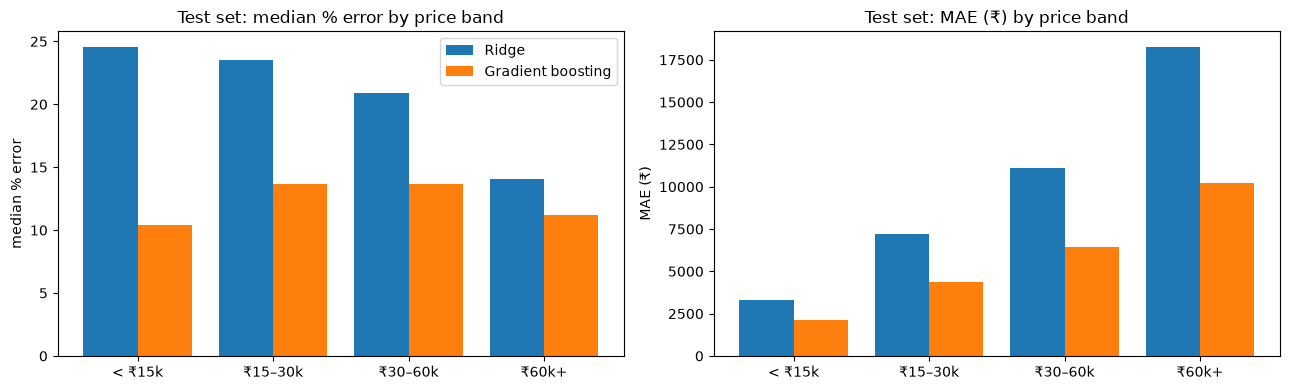

In [17]:
band = price_band(test["price_inr"])
by_band = {}
for name in ["Ridge", "Gradient boosting"]:
    price_pred = np.exp(pred[name])
    pct = pd.Series(100 * np.abs(price_pred / actual - 1), index=test.index)
    rupees = pd.Series(np.abs(price_pred - actual), index=test.index)
    by_band[(name, "median % error")] = pct.groupby(band, observed=True).median()
    by_band[(name, "MAE (₹)")] = rupees.groupby(band, observed=True).mean()
by_band = pd.DataFrame(by_band)
by_band[("phones", "")] = band.value_counts()
print(by_band.round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(len(by_band))
for ax, metric in zip(axes, ["median % error", "MAE (₹)"]):
    for j, name in enumerate(["Ridge", "Gradient boosting"]):
        ax.bar(x + (j - 0.5) * 0.4, by_band[(name, metric)], width=0.4, label=name)
    ax.set_xticks(x, by_band.index)
    ax.set(title=f"Test set: {metric} by price band", ylabel=metric)
axes[0].legend()
fig.tight_layout()
fig.savefig("../results/fig07_error_by_band.png", dpi=150)
plt.show()

**By brand.** Median % error per brand, only for brands with at least 5 test phones; with fewer phones one odd phone decides the result, so those brands are listed as "too few to judge".

In [18]:
counts = test["brand"].value_counts()
judged = counts[counts >= 5].index
by_brand = pd.DataFrame({name: pd.Series(100 * np.abs(np.exp(pred[name]) / actual - 1), index=test.index)
                         for name in ["Ridge", "Random forest", "Gradient boosting"]})
by_brand = by_brand[test["brand"].isin(judged)].groupby(test["brand"]).median().assign(phones=counts)
print(by_brand.sort_values("Gradient boosting").round(1).to_string())
print("\nToo few test phones to judge (< 5):", ", ".join(f"{b} ({n})" for b, n in counts[counts < 5].items()))

          Ridge  Random forest  Gradient boosting  phones
brand                                                    
Samsung    31.0           11.5                3.4       7
Oppo       20.5           13.4                7.7      15
OnePlus    13.5           10.4                8.3       6
Infinix    17.3           15.5               11.4      12
Apple      24.8           10.5               11.6      21
Xiaomi     20.4           10.5               13.1      13
Motorola   10.1            9.8               14.0      12
Vivo       24.3           16.2               15.1      29
Realme     31.6           11.4               16.2       8
POCO       19.4           22.8               24.3       5

Too few test phones to judge (< 5): Google (4), Tecno (4), Nokia (3), Other (3), Lenovo (2)


**The 10 largest misses of gradient boosting**, with the specs that matter most, so we can look for a reason. "% error" is predicted / actual − 1: positive = predicted too expensive.

In [19]:
gb_price = np.exp(pred["Gradient boosting"])
misses = test.assign(predicted=gb_price.round(-2), pct_error=100 * (gb_price / actual - 1),
                     ridge_pct=100 * (np.exp(pred["Ridge"]) / actual - 1))
misses = misses.reindex(misses["pct_error"].abs().sort_values(ascending=False).index[:10])
cols = ["Model Name", "brand", "price_inr", "predicted", "pct_error", "ridge_pct", "chip_group",
        "ram_gb", "storage_gb", "weight_g", "screen_in", "year"]
misses[cols].round(1)

,Model Name,brand,price_inr,predicted,pct_error,ridge_pct,chip_group,ram_gb,storage_gb,weight_g,screen_in,year
674,X3 Pro 128GB,POCO,18999.0,39000.0,105.1,84.2,flagship_sd8_or_apple,6.0,128.0,215.0,6.7,2021
206,T3 5G 128GB,Vivo,34999.0,68000.0,94.2,47.2,flagship_sd8_or_apple,8.0,128.0,180.0,6.7,2024
632,Note 40X 5G,Infinix,14999.0,29100.0,94.0,60.6,dimensity_other,8.0,256.0,198.0,6.8,2024
630,Hot 50 5G,Infinix,10999.0,17700.0,60.9,83.7,dimensity_other,8.0,128.0,195.0,6.8,2024
285,Reno13 Pro 512GB,Oppo,69999.0,108600.0,55.1,-5.2,dimensity_high,12.0,512.0,210.0,6.8,2025
271,T2 Series 128GB,Vivo,15999.0,24000.0,49.8,123.2,snapdragon_other,8.0,128.0,190.0,6.4,2023
633,Note 40 5G,Infinix,19999.0,29900.0,49.3,65.0,dimensity_high,8.0,256.0,195.0,6.8,2024
599,Spark 30 Pro 256GB,Tecno,19999.0,29500.0,47.6,44.7,helio,8.0,256.0,205.0,6.8,2024
429,C65 256GB,Realme,15999.0,23300.0,45.7,62.3,snapdragon_other,8.0,256.0,192.0,6.6,2024
272,T2 Series 256GB,Vivo,18999.0,26000.0,36.9,108.6,snapdragon_other,8.0,256.0,190.0,6.4,2023


**Takeaway — where the model fails.**

**By price band:** gradient boosting's median error is flat across bands (10.4 % under ₹15k, 13.7 % in the two middle bands, 11.2 % above ₹60k). Its MAE grows with price, from **₹2,113** to **₹10,250**, because the same % error is more rupees on an expensive phone. Ridge is worst on cheap phones (24.6 % under ₹15k, 23.6 % for ₹15–30k) and best on expensive ones (14.1 %), so the trees' gain is again mostly below ₹60,000, as in Phase 6.

**By brand** (≥ 5 test phones): boosting is excellent for Samsung (3.4 %, but only 7 phones) and Oppo (7.7 %). It is weakest for POCO (24.3 %, 5 phones), Realme (16.2 %) and Vivo (15.1 %). Ridge is much worse for most brands, with the largest gaps for Samsung (31.0 %), Realme (31.6 %), Apple (24.8 %) and Vivo (24.3 %).

**The 10 largest boosting misses: 9 of 10 are predicted too expensive**, all cheap or mid-priced phones from value-focused brands or sub-lines:
1. **POCO X3 Pro 128GB** (₹18,999, predicted ₹39,000, +105 %): its Snapdragon 860 matches our flagship rule ("Snapdragon 8xx"), so it counts as a flagship chip. It is an older flagship-class chip in a budget phone, a limitation of our chip grouping.
2. **Vivo T3 5G 128GB** (₹34,999, predicted ₹68,000, +94 %): the same issue. The dataset lists a Snapdragon 870, which our rule also counts as flagship, while phones with this chip in training cost ₹28,000–₹50,000.
3. **Infinix Note 40X 5G** (₹14,999, +94 %): price and storage come from our web lookup. Its specs (8 GB, 256 GB, 108 MP) look mid-range, but Infinix prices low. Reason beyond that: unclear.
4. **Infinix Hot 50 5G** (₹10,999, +61 %): web-lookup phone, budget brand. Unclear.
5. **Oppo Reno13 Pro 512GB** (₹69,999, predicted ₹1,08,600, +55 %): the only big miss on an expensive phone, and ridge got it nearly right (−5 %). Unclear why the trees overshoot.
6. and 10. **Vivo T2 Series 128GB / 256GB** (+50 % / +37 %; ridge was even worse, +123 % / +109 %): Vivo's T line is priced well below Vivo's usual level, but the model only knows "Vivo". (The name "T2 Series" may also mix several models; unclear.)
7. **Infinix Note 40 5G** (₹19,999, +49 %): web-lookup phone. The dataset lists a Dimensity 8100 (our `dimensity_high` group), which is a high-end chip for a ₹19,999 phone. This may be a data mismatch; unclear.
8. **Tecno Spark 30 Pro 256GB** (₹19,999, +48 %): a budget brand selling 8 GB + 256 GB cheaply. Unclear.
9. **Realme C65 256GB** (₹15,999, +46 %): Realme's budget C line with 8 GB + 256 GB. Unclear.

**Same kinds of phones as in Phase 4?** Partly yes. Phase 4's largest misses were Oppo's K-series and A49, budget lines priced far below what their specs suggest, and the Vivo X200, a flagship priced above. The test set has no Oppo K phones, but the same pattern returns: **value sub-lines of a brand** (Vivo T, Realme C, Infinix, POCO) that give generous RAM and storage for a low price. The model learns one "brand level" plus specs, so it cannot know that a brand prices one product line much lower. A second, new failure is our **chip grouping**: old flagship chips (Snapdragon 860/870) in later mid-range phones are treated as current flagships. Three of the ten misses are web-lookup Infinix phones.

## 7.7 Robustness: name-only data
We refit ridge and gradient boosting on the name-only training data (without the web-lookup phones) and score them on the name-only test set (web-lookup phones removed from the test set too), with the same settings.

In [20]:
train_name, test_name = load_train_test(include_web_lookup=False)
rob = []
for name in ["Ridge", "Gradient boosting"]:
    model = clone(pipelines[name]).fit(train_name[FEATURES], train_name["log_price"])   # fresh copy, same settings
    s_name = score(test_name["log_price"], model.predict(test_name[FEATURES]))
    for label, s, n in [("with web lookup", test_scores.loc[name], len(test)), ("name-only", s_name, len(test_name))]:
        rob.append({"model": name, "data": label, "test phones": n, "R²": round(s["R²"], 3),
                    "median % error": round(s["median % error"], 1), "MAE (₹)": round(s["MAE (₹)"])})
pd.DataFrame(rob)

,model,data,test phones,R²,median % error,MAE (₹)
0,Ridge,with web lookup,144,0.849,21.5,10443
1,Ridge,name-only,140,0.858,20.7,10422
2,Gradient boosting,with web lookup,144,0.932,12.4,6050
3,Gradient boosting,name-only,140,0.938,12.0,6235


**Takeaway:** removing the 4 web-lookup phones from the test set (and the 3 from the training set) changes little. Ridge goes from R² 0.849 / 21.5 % to 0.858 / 20.7 %, and gradient boosting from 0.932 / 12.4 % to **0.938 / 12.0 %**. Both improve slightly, because three of those four Infinix phones are among the hardest test phones. The conclusions are unchanged.

### Robustness: phones with a doubtful India price
Notebook 01 added `india_price_flag` for phones whose India price may not be a real Indian launch price: Huawei phones launched after 2019 (not officially sold in India) and phones whose India/China price ratio is an outlier for their brand. Here we **rescore** ridge and gradient boosting on the test set **without the flagged test phones**, using the predictions already made above. Nothing is refitted or tuned.

In [21]:
flagged = (test["india_price_flag"].fillna("") != "").to_numpy()
print(f"flagged test phones: {flagged.sum()} of {len(test)}:", ", ".join(test.loc[flagged, "brand"] + " " + test.loc[flagged, "Model Name"]))
rows = []
for name in ["Ridge", "Gradient boosting"]:
    s_clean = score(y_test[~flagged], pred[name][~flagged])
    for label, s, n in [("all test phones", test_scores.loc[name], len(test)), ("flagged removed", s_clean, int((~flagged).sum()))]:
        rows.append({"model": name, "test phones": label, "n": n, "R²": round(s["R²"], 3),
                     "median % error": round(s["median % error"], 2), "MAE (₹)": round(s["MAE (₹)"])})
pd.DataFrame(rows)

flagged test phones: 2 of 144: OnePlus OnePlus 9 Pro 256GB, Other Xperia 1 IV 256GB


,model,test phones,n,R²,median % error,MAE (₹)
0,Ridge,all test phones,144,0.849,21.53,10443
1,Ridge,flagged removed,142,0.846,21.73,10576
2,Gradient boosting,all test phones,144,0.932,12.36,6050
3,Gradient boosting,flagged removed,142,0.931,12.41,6000


**Takeaway:** only **2 of the 144 test phones** are flagged (OnePlus 9 Pro 256GB and Sony Xperia 1 IV 256GB, both for an unusual India/China price ratio; the flagged Huawei phones are all in the training set). Removing them barely changes the scores: ridge goes from R² 0.849 / 21.53 % to 0.846 / 21.73 %, and gradient boosting from 0.932 / 12.36 % to 0.931 / 12.41 % (median error changes of 0.2 and 0.05 points, far below the bootstrap noise). The test results do not depend on the doubtful India prices.

## 7.8 Save the results
`results/test_scores.csv` (all metrics per model, with CV for comparison) and `results/test_bootstrap.csv` (95 % intervals per model and the paired differences).

In [22]:
test_scores.join(versus[["CV R²", "CV median %"]]).to_csv("../results/test_scores.csv")
boot_table = pd.concat([intervals.assign(kind="model"), paired.assign(kind="paired difference")])
boot_table.to_csv("../results/test_bootstrap.csv", index_label="name")
print("Saved results/test_scores.csv and results/test_bootstrap.csv")

Saved results/test_scores.csv and results/test_bootstrap.csv


## Results paragraph (for the website)
On 144 phones the models had never seen, **gradient boosting priced phones best**. It reached R² **0.93** on log price (95 % bootstrap interval 0.90–0.96) and a median error of **12.4 %** (9.6–14.3 %): half of the test phones were priced within 12.4 % of their actual launch price, and 72 % within ±20 %. That is a large improvement over simply knowing the brand (median error 33.5 %) or guessing the average price (58.7 %). The random forest was practically as good (12.7 %); the two cannot be separated on this test set. **Ridge regression**, our interpretable linear model, reached R² 0.85 and a median error of 21.5 % (15.9–26.3 %). Boosting's advantage over ridge is clearly real: 9 points of median error (95 % interval 3–15 points), better in 99.9 % of bootstrap resamples. We still keep ridge for interpretation and for measuring the brand premium, because its coefficients have a direct meaning. The models fail mainly on cheap phones from value-focused product lines (e.g. Vivo T, Realme C, Infinix, POCO), which offer generous specs at low prices that the model cannot anticipate, and on mid-range phones with an older flagship chip. Test scores were close to the cross-validation scores (boosting R² 0.91 in CV vs 0.93 on test), so we found no measurable overfitting from tuning.

## Summary
- **Best model on the test set:** gradient boosting, R² **0.932** (0.897–0.955) and median error **12.4 %** (9.6–14.3 %). The random forest is tied (0.925, 12.7 %). AdaBoost, added later with settings fixed by cross-validation, is also close (0.926, 13.3 %) and cannot be separated from gradient boosting.
- **Trees vs linear:** clearly better than ridge (−9.2 points of median error, interval −14.6 to −2.8; R² +0.08). Ridge, lasso, elastic net and OLS Model B are statistically indistinguishable (all R² ≈ 0.85, about 21 % median error).
- **CV → test:** no measurable drop. The trees scored slightly better on test than in CV, and the linear models' median error rose by about 3 points, all within the bootstrap noise of a 144-phone test set.
- **Where it fails:** cheap and mid-priced phones from value lines and value brands (POCO, Vivo T, Realme C, Infinix, Tecno) are predicted too expensive. Two misses come from our chip grouping (old Snapdragon 860/870 counted as flagship). The % error is flat across price bands for boosting, while ridge is worst below ₹30,000.
- **Saved for later phases:** `results/test_predictions.csv`, `test_scores.csv`, `test_bootstrap.csv`, three figures (PNG) plus `fig07_pred_vs_actual.json` for the website, and the fitted ridge, Model A and gradient boosting models in `models/`.

## Changes after unlocking the test set
None. The notebook was first checked end-to-end on a stand-in split (training fold 1 used as a pretend test set) before the real test set was loaded. It was then run once on the real test set. After that, only the markdown takeaways were written; no code, model, feature or setting was changed, and the code cells were not rerun.

Issues noticed in the test results and deliberately **not** fixed here (they would change the features after seeing the test set; record them as limitations or address them in a future version validated with new data):
- The chip rule counts the Snapdragon 860 and 870 (older flagship-class chips sold in later mid-range phones) as `flagship_sd8_or_apple`.
- The dataset's chip for the Infinix Note 40 5G (Dimensity 8100) may not match the actual phone.

**Added later (at the team's request, after the data-quality check in notebook 01):** a robustness check that rescores ridge and gradient boosting on the test set without phones flagged by `india_price_flag`. It uses the predictions already made; no model, feature or setting was changed. Because notebook 01 added this column, the notebook was rerun from the top; all earlier outputs are unchanged.

AdaBoost was added in a later iteration to cover a course topic. Its settings were fixed by grouped cross-validation on the training set (notebook 05) before it was scored on the test set once.